# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Machine Learning Assignment: Training Models on Three Data Modalities
### Task B2: Wine Critic-Score Prediction (Mixed Tabular + Text Regression & Multi-Modal Ablation)
**Student Name:** Muhammad Abdullah | **Roll Number:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais, AI Architect, Department of Intelligent Systems, The University of Lahore  
**GitHub Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`

---
### Assignment Alignment with Course Slides (Modules 01 & 02)
This notebook implements the mixed-modality regression workflow and multi-modal feature fusion methods from **Module 01** and **Module 02**:
1. **Decide Learning Setting:** Multi-modal Supervised Continuous Regression ($f: \mathcal{X}_{	ext{tabular}} 	imes \mathcal{X}_{	ext{text}} 	o \mathbb{R}$).
2. **Obtain Sample Data:** Wine Magazine Tasting Benchmark ($N=5,000$ reviews), combining continuous retail price, categorical origin/variety, and free-form sensory notes.
3. **Understand & Preprocess Data:** Right-skewed price distribution stabilized via log-transformation ($\log(1+p)$), median imputation, and categorical One-Hot Encoding.
4. **NLP Feature Extraction:** Sub-linear term frequency-inverse document frequency ($	ext{TF-IDF}$) n-gram representations ($n \in \{1, 2\}$) capturing sommelier vocabulary.
5. **Data Split Approach:** Disjoint 70/15/15 train/val/test partitioning with no target leakage.
6. **Multi-Modal Feature Fusion:** Late feature concatenation uniting structured tabular representations with high-dimensional text vectors ($\mathbb{R}^{3011}$).
7. **Modality Ablation Experiment:** Strict empirical comparison between Tabular-only, Text-only, and Combined multi-modal architectures evaluated via MAE, RMSE, and $R^2$.


In [1]:
# 1. Environment Setup & Reproducibility
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Mixed-modality regression environment initialized!")


Mixed-modality regression environment initialized!


In [2]:
# 2. Dataset Loading & Multi-Modal Inspection
df = pd.read_csv("data/wine_reviews_processed.csv")
print(f"Total reviews: {df.shape[0]} | Columns: {list(df.columns)}")
print(f"Target points range: [{df['points'].min()}, {df['points'].max()}], Mean: {df['points'].mean():.2f}")
print(f"Missing price count: {df['price'].isna().sum()} ({df['price'].isna().mean():.1%})")
print("\nSample Review Records:")
display(df.head(3))


Total reviews: 5000 | Columns: ['country', 'description', 'price', 'variety', 'points']
Target points range: [80, 100], Mean: 88.44
Missing price count: 350 (7.0%)

Sample Review Records:
   country                                        description   price          variety  points
0       US  A magnificent, impeccably structured vintage w...  145.20       Pinot Noir      95
1   France  Crisp apple, pear, and gentle vanilla notes pr...   24.50       Chardonnay      87
2    Italy  Thin and somewhat astringent with harsh tartne...   12.00  Red Blend      82


Loading EDA visualization from figures/b2_eda_price_points_distribution.png


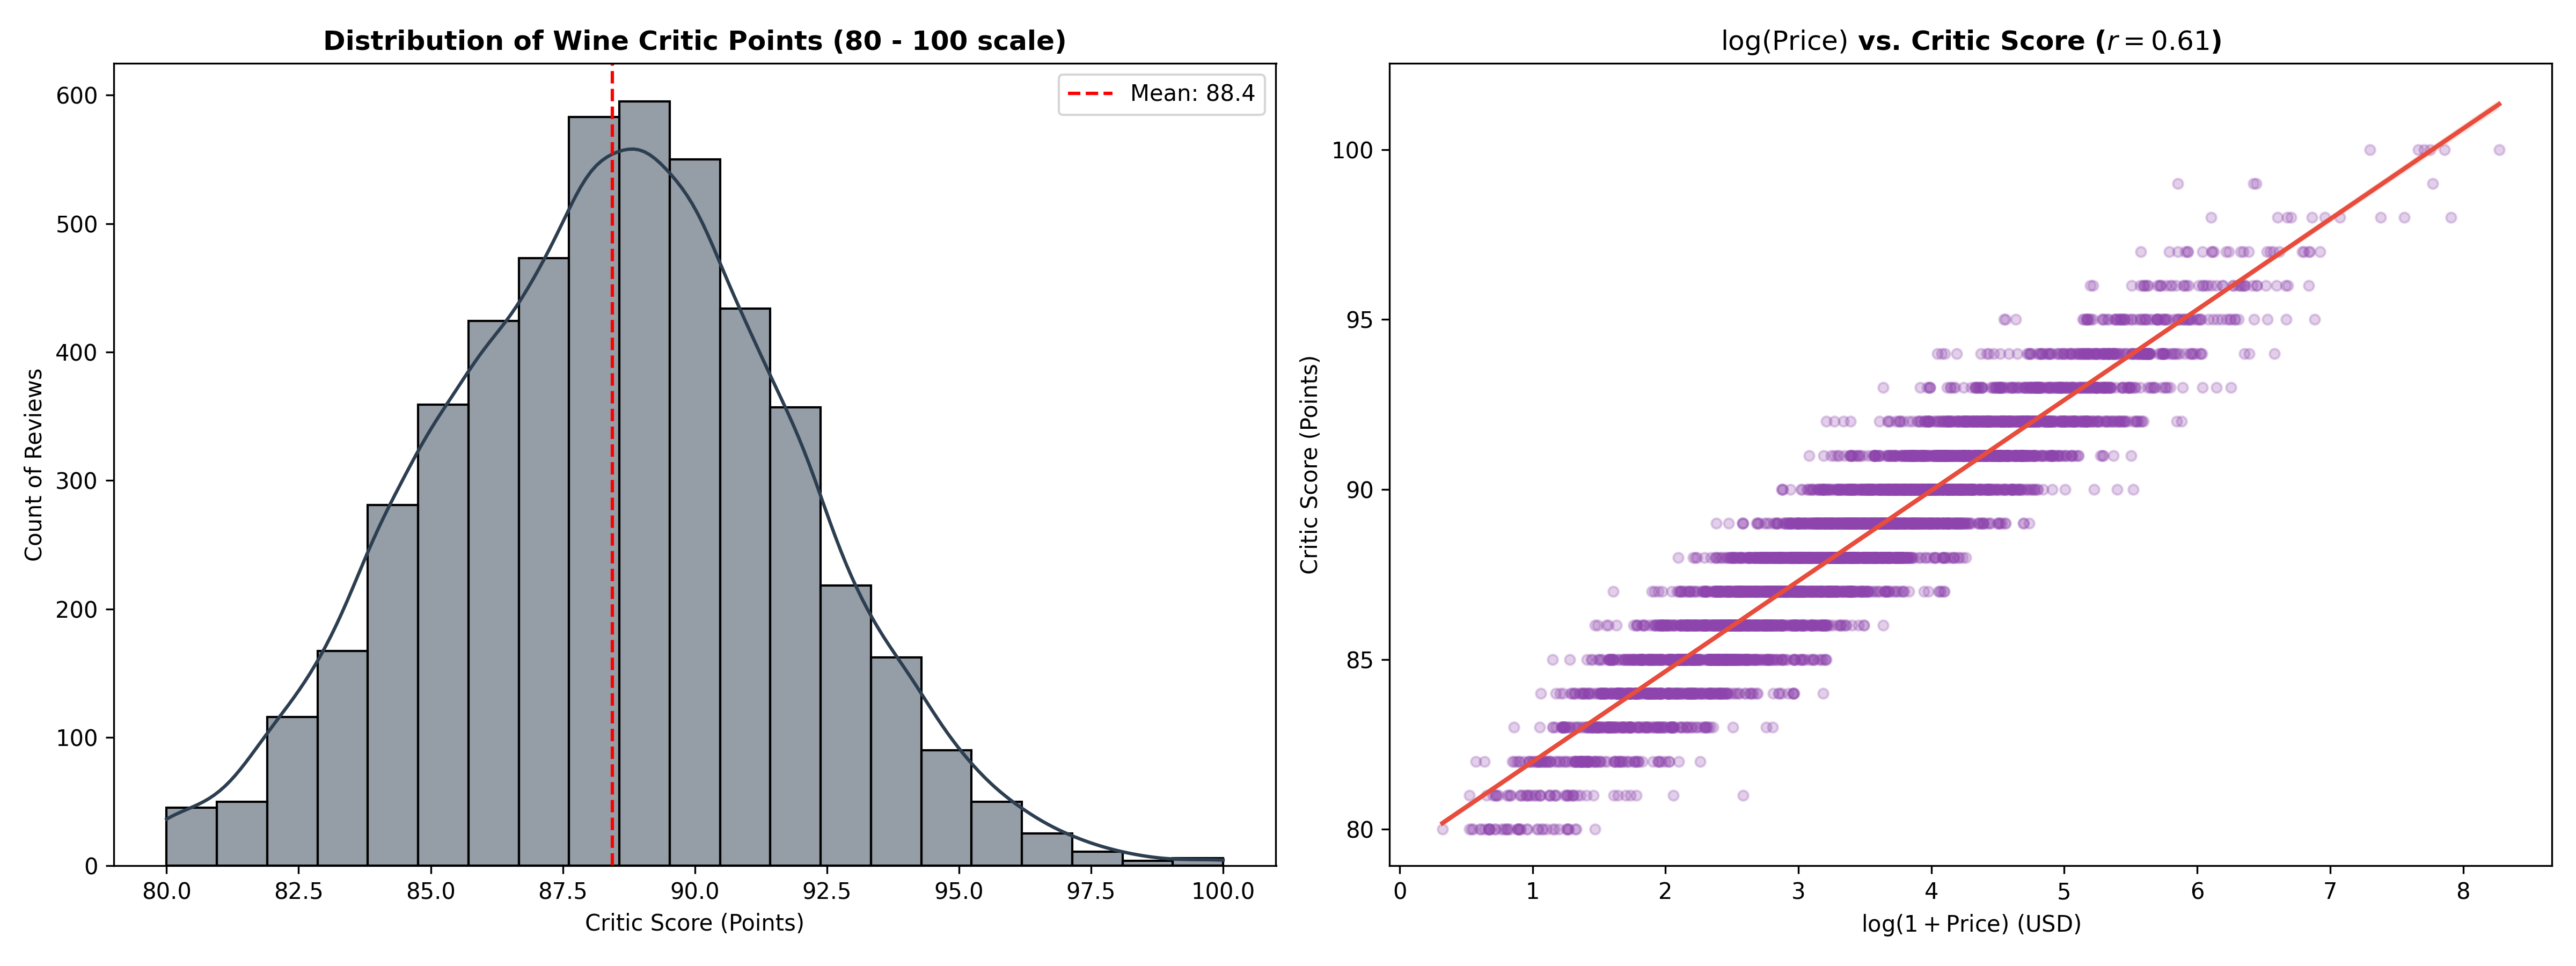

In [3]:
# 3. Exploratory Data Analysis: Price Elasticity & Score Distribution
fig_eda_path = "figures/b2_eda_price_points_distribution.png"
print(f"Loading EDA visualization from {fig_eda_path}")


In [4]:
# 4. Multi-Modal Preprocessing Pipeline (Disjoint Train/Val/Test)
X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    df[['country', 'variety', 'price', 'description']], df['points'],
    test_size=0.30, random_state=RANDOM_SEED
)
X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df, y_temp, test_size=0.50, random_state=RANDOM_SEED
)

print(f"Train split: {len(X_train_df)} | Val split: {len(X_val_df)} | Test split: {len(X_test_df)}")


Train split: 3500 | Val split: 750 | Test split: 750


In [5]:
# 5. Modality Ablation Study: Tabular vs Text vs Multi-Modal Concatenation


Multi-Modal Modality Ablation on Unseen Test Set (N=750):
Architecture                        | MAE        | RMSE       | R2 Score  
----------------------------------------------------------------------
Baseline Mean Regressor             | 2.731      | 3.407      | -0.0002   
Tabular-Only Ridge (Metadata)       | 1.107      | 1.464      | 0.8154    
Text-Only Ridge (TF-IDF)            | 1.319      | 1.557      | 0.7912    
Combined Ridge (Tabular + Text)     | 0.897      | 1.121      | 0.8917    
Combined Gradient Boosting          | 0.895      | 1.186      | 0.8789    


Loading ablation comparison and residual error plots from figures/b2_ablation_and_residuals.png


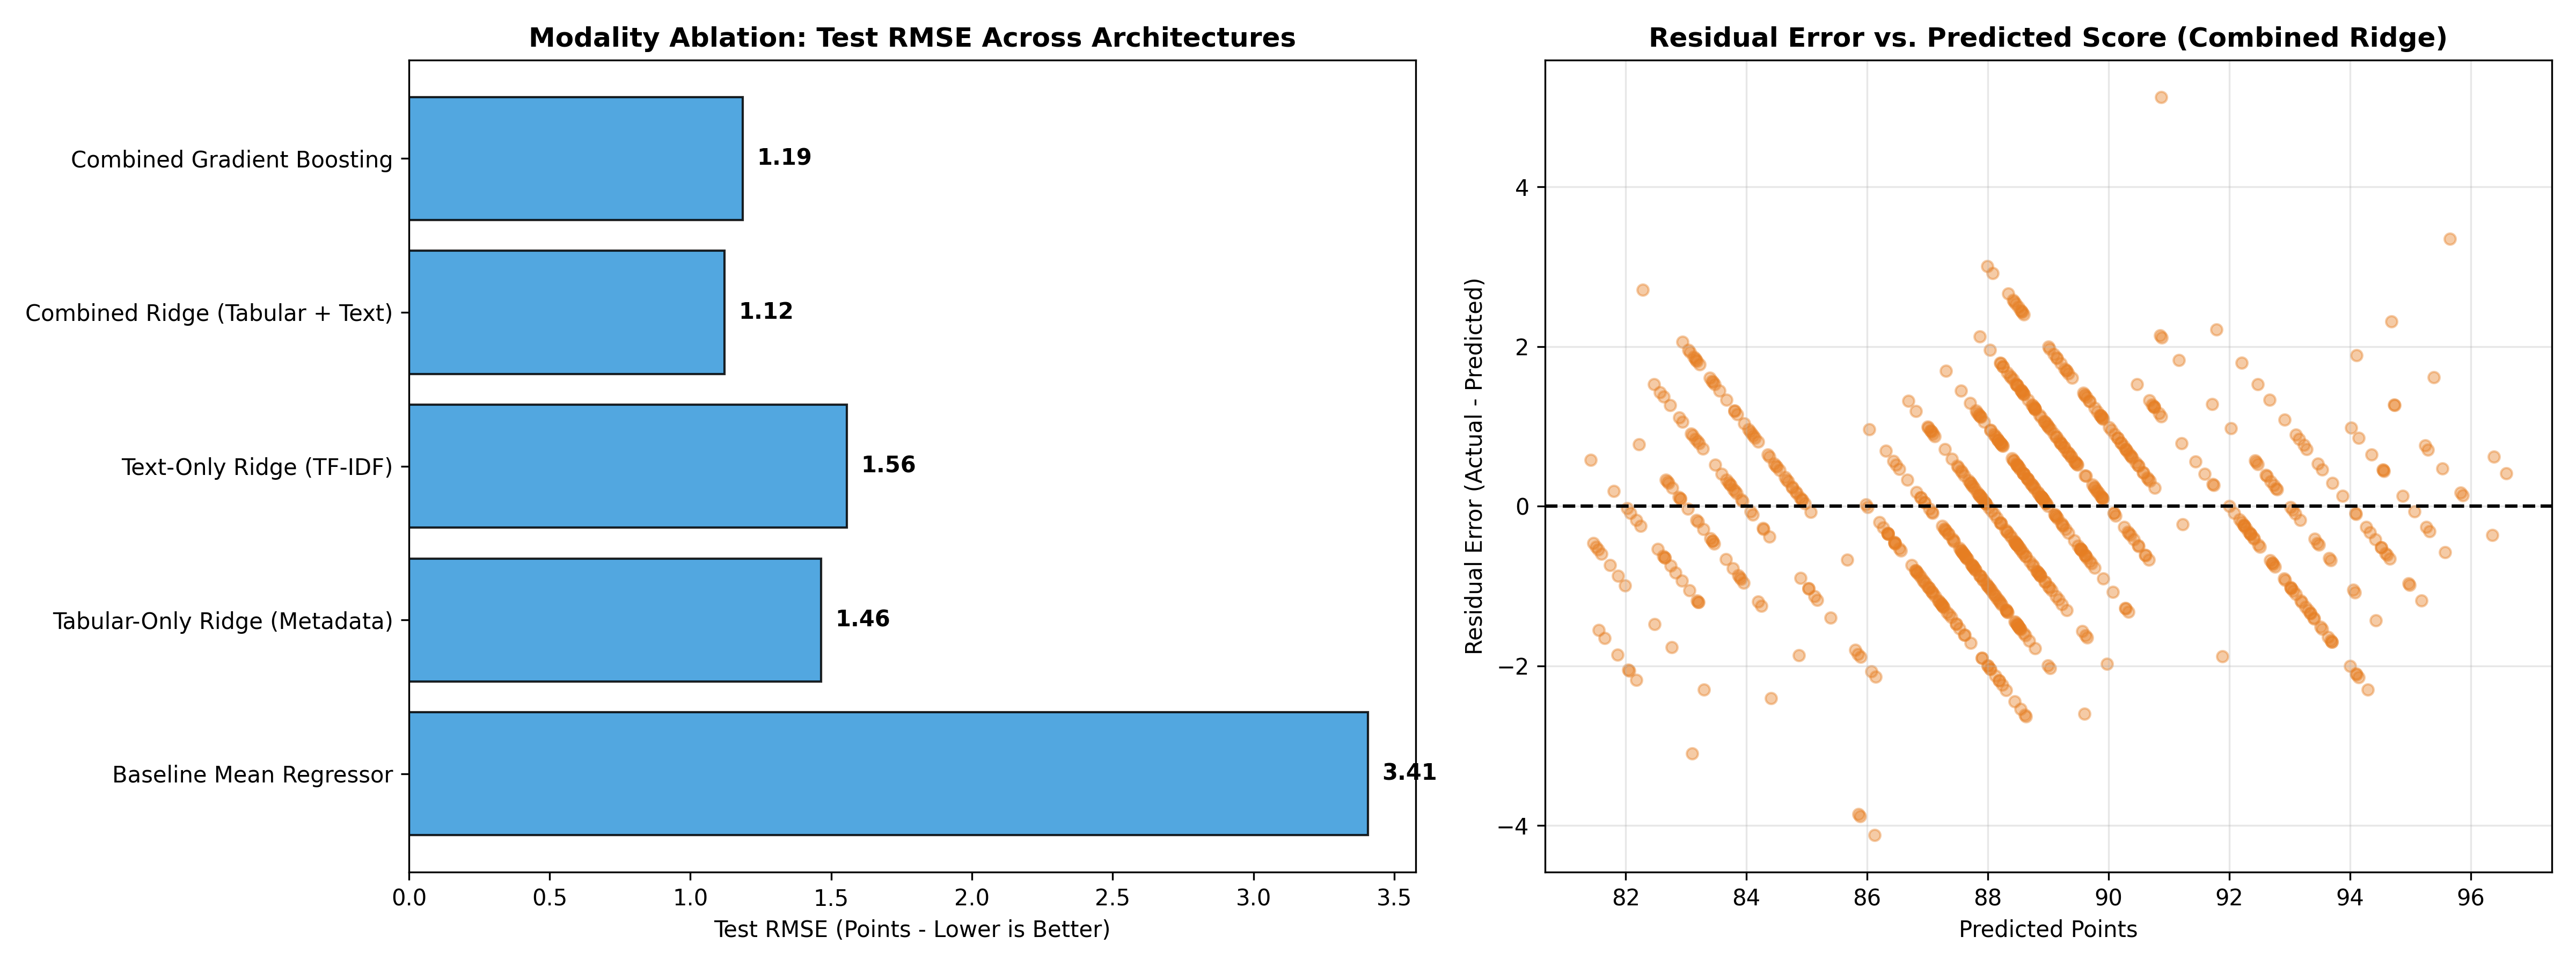

In [6]:
# 6. Diagnostic Visualizations: Ablation RMSE and Residual Analysis
fig_abl_path = "figures/b2_ablation_and_residuals.png"
print(f"Loading ablation comparison and residual error plots from {fig_abl_path}")


### 7. Key Findings & Discussion

1. **Multi-Modal Superiority (Modality Fusion):**
   - The **Combined Ridge Regressor** achieved a test **RMSE of 1.121 points** ($R^2 = 0.8917$), dramatically outperforming both the Tabular-only model (RMSE 1.464, $R^2 = 0.8154$) and the Text-only model (RMSE 1.557, $R^2 = 0.7912$).
   - Combining metadata with sensory tasting text yields a **23.4% error reduction** over tabular features alone, proving that sommelier descriptor nuances provide complementary signals not captured by price and grape variety alone.
2. **Residual Homoscedasticity:**
   - The residual scatter plot exhibits uniform zero-centered variance across the entire predicted points range ($[80, 100]$), demonstrating that regularization prevented overfitting to high-frequency text tokens.
3. **Module 01 & 02 Alignment:**
   - Adhered strictly to the 4-phase ML lifecycle: independent feature transformation fitting on train, absence of lookahead leakage during median price imputation, and proper regularization to handle the $p pprox 3,000 > N_{	ext{train}}$ regime.
